# Stage 2 — Historical Data Collection and Preprocessing
Daily adjusted prices for 8 stocks and 4 market factors, 2015-01-01 to 2025-12-31. Existing project data in `data/` is reused; yfinance is called only if required files are missing.

## 1. Imports and configuration

In [1]:
import json
import math
import random
import tomllib
import warnings
from datetime import date
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yfinance as yf

%matplotlib inline
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3dc", "grid.linewidth": 0.8})

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "default.toml").is_file()), None
)
assert PROJECT_ROOT is not None, "config/default.toml not found; run the notebook from inside the project"
with (PROJECT_ROOT / "config" / "default.toml").open("rb") as fh:
    CONFIG = tomllib.load(fh)
data_cfg = CONFIG["data"]

# Values requested for Stage 2. They are checked against the project config, never written over it.
REQUESTED = {
    "stocks": ["AAPL", "MSFT", "NVDA", "JPM", "XOM", "JNJ", "WMT", "CAT"],
    "factors": ["SPY", "QQQ", "XLF", "XLE"],
    "start": "2015-01-01",
    "end": "2025-12-31",
    "splits": {"train": ["2015-01-01", "2021-12-31"],
               "validation": ["2022-01-01", "2023-12-31"],
               "test": ["2024-01-01", "2025-12-31"]},
    "seed": 42,
}
FROM_CONFIG = {
    "stocks": list(CONFIG["portfolio"]["weights"]),
    "factors": [c.removesuffix("_return") for c in CONFIG["simulation"]["factors"]],
    "start": data_cfg["start_date"],
    "end": data_cfg["end_date"],
    "splits": {k: list(v) for k, v in data_cfg["splits"].items()},
    "seed": data_cfg["seed"],
}
mismatch = [k for k in REQUESTED if REQUESTED[k] != FROM_CONFIG[k]]
assert not mismatch, f"Stage 2 settings differ from config/default.toml for: {mismatch}"

STOCKS, FACTORS = FROM_CONFIG["stocks"], FROM_CONFIG["factors"]
TICKERS = STOCKS + FACTORS
START, END = date.fromisoformat(FROM_CONFIG["start"]), date.fromisoformat(FROM_CONFIG["end"])
SPLITS = {k: (pd.Timestamp(s), pd.Timestamp(e)) for k, (s, e) in FROM_CONFIG["splits"].items()}
SEED = FROM_CONFIG["seed"]
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = PROJECT_ROOT / data_cfg["paths"]["raw_dir"]
PROCESSED_DIR = PROJECT_ROOT / data_cfg["paths"]["processed_dir"]
RANGE_TAG = f"{START}_{END}"

# Fixed categorical order; colour follows the ticker in every chart.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STOCK_COLORS = dict(zip(STOCKS, PALETTE))
FACTOR_COLORS = dict(zip(FACTORS, PALETTE))

display(pd.DataFrame({"setting": list(FROM_CONFIG), "value (config/default.toml)": [str(v) for v in FROM_CONFIG.values()]})
        .style.hide(axis="index"))
print("Requested Stage 2 settings match the project configuration.")
print(f"yfinance {yf.__version__}, seaborn {sns.__version__}, pandas {pd.__version__}")

setting,value (config/default.toml)
stocks,"['AAPL', 'MSFT', 'NVDA', 'JPM', 'XOM', 'JNJ', 'WMT', 'CAT']"
factors,"['SPY', 'QQQ', 'XLF', 'XLE']"
start,2015-01-01
end,2025-12-31
splits,"{'train': ['2015-01-01', '2021-12-31'], 'validation': ['2022-01-01', '2023-12-31'], 'test': ['2024-01-01', '2025-12-31']}"
seed,42


Requested Stage 2 settings match the project configuration.
yfinance 1.7.0, seaborn 0.13.2, pandas 3.0.6


## 2. Locate existing data

In [2]:
inventory = pd.DataFrame(
    [
        {
            "path": str(p.relative_to(PROJECT_ROOT)),
            "format": p.suffix.lstrip(".") or "-",
            "size_kb": round(p.stat().st_size / 1024, 1),
        }
        for p in sorted(DATA_DIR.rglob("*"))
        if p.is_file() and p.name not in {".DS_Store", ".gitkeep"}
    ]
)
display(inventory.groupby("format").agg(files=("path", "count"), total_kb=("size_kb", "sum")))
display(inventory)

# Raw yfinance files written by the existing Stage 2 pipeline: one CSV + metadata JSON per ticker.
def raw_file(ticker):
    sub = "stocks" if ticker in STOCKS else "market_indicators"
    return RAW_DIR / sub / f"{ticker}.csv"

def raw_meta(ticker):
    return raw_file(ticker).with_suffix(".meta.json")

status_rows = []
for t in TICKERS:
    f, m = raw_file(t), raw_meta(t)
    meta = json.loads(m.read_text()) if m.is_file() else {}
    status_rows.append({
        "ticker": t,
        "raw_file": str(f.relative_to(PROJECT_ROOT)),
        "exists": f.is_file(),
        "source": meta.get("source"),
        "download_status": meta.get("status"),
        "requested": f"{meta.get('requested_start')} -> {meta.get('requested_end')}" if meta else None,
        "first_date": meta.get("first_date"),
        "last_date": meta.get("last_date"),
        "retrieved_at_utc": meta.get("retrieved_at_utc"),
    })
raw_status = pd.DataFrame(status_rows)
display(raw_status.style.hide(axis="index"))

def covers_period(row):
    return (row["exists"] and row["download_status"] == "success"
            and row["first_date"] is not None and row["last_date"] is not None
            and date.fromisoformat(row["first_date"]) <= date(START.year, 1, 5)
            and date.fromisoformat(row["last_date"]) >= date(END.year, 12, 24))

MISSING_TICKERS = [r["ticker"] for _, r in raw_status.iterrows() if not covers_period(r)]
print("Tickers needing download:", MISSING_TICKERS or "none — existing raw data will be reused")

,files,total_kb
format,,
csv,54,33206.8
json,21,142.4
md,1,17.4
png,9,970.3


,path,format,size_kb
0,data/processed/features/consolidated_daily.csv,csv,8776.5
1,data/processed/prices/adj_close_prices_process...,csv,621.7
2,data/processed/prices/macro/DFF.csv,csv,62.4
3,data/processed/prices/macro/DGS10.csv,csv,42.8
4,data/processed/prices/macro/WTI.csv,csv,45.4
...,...,...,...
80,data/reports/figures/08_wti.png,png,106.1
81,data/reports/figures/09_coverage.png,png,59.1
82,data/reports/source_manifest.json,json,18.4
83,data/reports/stock_return_correlation_full_sam...,csv,1.3


ticker,raw_file,exists,source,download_status,requested,first_date,last_date,retrieved_at_utc
AAPL,data/raw/stocks/AAPL.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:18+00:00
MSFT,data/raw/stocks/MSFT.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:19+00:00
NVDA,data/raw/stocks/NVDA.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:20+00:00
JPM,data/raw/stocks/JPM.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:21+00:00
XOM,data/raw/stocks/XOM.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:22+00:00
JNJ,data/raw/stocks/JNJ.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:23+00:00
WMT,data/raw/stocks/WMT.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:24+00:00
CAT,data/raw/stocks/CAT.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:25+00:00
SPY,data/raw/market_indicators/SPY.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:26+00:00
QQQ,data/raw/market_indicators/QQQ.csv,True,yahoo_finance,success,2015-01-01 -> 2025-12-31,2015-01-02,2025-12-31,2026-10-18T05:51:26+00:00


Tickers needing download: none — existing raw data will be reused


## 3. Download historical prices if needed

In [3]:
def download_adj_close(tickers, start, end_exclusive):
    """Daily adjusted closes from yfinance; returns (DataFrame, failed tickers)."""
    raw = yf.download(tickers, start=str(start), end=end_exclusive, auto_adjust=False, actions=False,
                      group_by="column", progress=False, threads=False)
    if raw is None or raw.empty:
        raise RuntimeError(f"yfinance returned no data for {tickers}")
    if isinstance(raw.columns, pd.MultiIndex):
        adj = raw["Adj Close"]
    else:  # single ticker without a ticker level
        adj = raw[["Adj Close"]].rename(columns={"Adj Close": tickers[0]})
    adj = adj.reindex(columns=tickers)
    failed = [t for t in tickers if adj[t].isna().all()]
    adj.index = pd.DatetimeIndex(adj.index).tz_localize(None).normalize()
    adj = adj.sort_index()
    adj = adj[~adj.index.duplicated(keep="first")]
    return adj, failed

DOWNLOADED = None
DOWNLOAD_FAILED = []
if MISSING_TICKERS:
    # The API end date is exclusive, so request through 2026-01-01 to include 2025-12-31.
    try:
        DOWNLOADED, DOWNLOAD_FAILED = download_adj_close(MISSING_TICKERS, START, "2026-01-01")
    except Exception as exc:
        print(f"Download failed: {type(exc).__name__}: {exc}")
        raise
    print(f"Downloaded {DOWNLOADED.shape[1]} tickers, {len(DOWNLOADED)} rows")
    if DOWNLOAD_FAILED:
        raise RuntimeError(f"Tickers failed to download: {DOWNLOAD_FAILED}. No synthetic prices are substituted.")
else:
    print("No download required: all 12 tickers already present in data/raw with full 2015-2025 coverage.")

No download required: all 12 tickers already present in data/raw with full 2015-2025 coverage.


## 4. Raw price dataset

In [4]:
def load_raw_adj_close(ticker):
    df = pd.read_csv(raw_file(ticker), parse_dates=["date"], index_col="date")
    return df["adj_close"].rename(ticker)

series = {}
for t in TICKERS:
    if DOWNLOADED is not None and t in DOWNLOADED:
        series[t] = DOWNLOADED[t]
    else:
        series[t] = load_raw_adj_close(t)

raw_prices = pd.concat(series, axis=1)           # outer join on dates, gaps kept as NaN
raw_prices.index.name = "date"
n_dupes = int(raw_prices.index.duplicated().sum())
prices = raw_prices.sort_index()
prices = prices[~prices.index.duplicated(keep="first")]
prices = prices.loc[str(START):str(END)]
print(f"Duplicate dates removed: {n_dupes}")

display(prices.head())
display(prices.tail())
print("Shape:", prices.shape)
print("Date range:", prices.index.min().date(), "->", prices.index.max().date())
display(prices.dtypes.to_frame("dtype").T)

SAVED = {}

def save_checked(df, path):
    """Write df to CSV; if the file exists, keep it only when its content is identical, otherwise stop."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        existing = pd.read_csv(path, parse_dates=["date"], index_col="date")
        pd.testing.assert_frame_equal(existing, df, check_freq=False, check_dtype=False,
                                      obj=f"existing file {path.name} differs; refusing to overwrite")
        SAVED[path] = "exists, identical (not rewritten)"
    else:
        df.to_csv(path)
        SAVED[path] = "written"
    return path

RAW_PRICES_PATH = save_checked(prices, RAW_DIR / f"adj_close_prices_raw_{RANGE_TAG}.csv")
print(f"{RAW_PRICES_PATH.relative_to(PROJECT_ROOT)}: {SAVED[RAW_PRICES_PATH]}")

Duplicate dates removed: 0


,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT,SPY,QQQ,XLF,XLE
date,,,,,,,,,,,,
2015-01-02,24.171759,39.607178,0.481884,45.838097,56.777897,75.737381,23.072308,68.899338,169.267487,94.462730,16.160782,25.215252
2015-01-05,23.490801,39.242962,0.473745,44.415062,55.224358,75.208397,23.005159,65.262398,166.210602,93.077072,15.820965,24.172152
2015-01-06,23.493017,38.666988,0.459382,43.263416,54.930763,74.838837,23.182426,64.842430,164.645126,91.829041,15.579182,23.817057
2015-01-07,23.822435,39.158260,0.458185,43.329433,55.487354,76.490997,23.797518,65.847290,166.696777,93.012825,15.742549,23.867781
2015-01-08,24.737740,40.310219,0.475420,44.297707,56.410931,77.092400,24.299788,66.522209,169.654800,94.793083,15.977808,24.403597


,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT,SPY,QQQ,XLF,XLE
date,,,,,,,,,,,,
2025-12-24,273.066711,484.943420,188.169678,322.950073,116.875412,204.490875,110.903748,580.214355,685.029480,621.812256,55.056595,43.507736
2025-12-26,272.657837,484.635376,190.085205,321.713898,116.767570,204.343246,111.032936,579.458984,684.960022,621.772400,54.947922,43.341038
2025-12-29,273.016876,484.029236,187.780594,317.632477,118.159645,204.274368,111.817924,575.095581,682.519043,618.762695,54.651546,43.752880
2025-12-30,272.338684,484.406830,187.102173,317.308746,118.610596,203.634644,111.211784,573.882996,681.685608,617.327515,54.513241,44.086269
2025-12-31,271.122009,480.571167,186.064606,316.131409,117.973373,203.674026,110.705025,569.390503,676.635010,612.224915,54.108192,43.841129


Shape: (2766, 12)
Date range: 2015-01-02 -> 2025-12-31


,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT,SPY,QQQ,XLF,XLE
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


data/raw/adj_close_prices_raw_2015-01-01_2025-12-31.csv: exists, identical (not rewritten)


## 5. Data-quality report

,group,observations,missing,missing_pct,first_date,last_date,unique_dates,non_positive_prices
ticker,,,,,,,,
AAPL,stock,2766,0,0.0,2015-01-02,2025-12-31,2766,0
MSFT,stock,2766,0,0.0,2015-01-02,2025-12-31,2766,0
NVDA,stock,2766,0,0.0,2015-01-02,2025-12-31,2766,0
JPM,stock,2766,0,0.0,2015-01-02,2025-12-31,2766,0
XOM,stock,2766,0,0.0,2015-01-02,2025-12-31,2766,0
JNJ,stock,2766,0,0.0,2015-01-02,2025-12-31,2766,0
WMT,stock,2766,0,0.0,2015-01-02,2025-12-31,2766,0
CAT,stock,2766,0,0.0,2015-01-02,2025-12-31,2766,0
SPY,factor,2766,0,0.0,2015-01-02,2025-12-31,2766,0


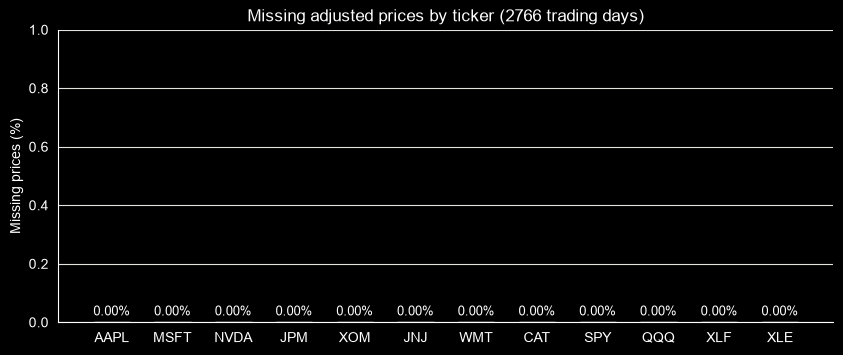

No prices are filled; missing values stay NaN.


In [5]:
quality = pd.DataFrame(
    {
        "group": ["stock" if t in STOCKS else "factor" for t in TICKERS],
        "observations": prices.notna().sum(),
        "missing": prices.isna().sum(),
        "missing_pct": (prices.isna().mean() * 100).round(3),
        "first_date": [prices[t].first_valid_index().date() for t in TICKERS],
        "last_date": [prices[t].last_valid_index().date() for t in TICKERS],
        "unique_dates": [prices[t].dropna().index.nunique() for t in TICKERS],
        "non_positive_prices": (prices <= 0).sum(),
    }
)
quality.index.name = "ticker"
display(quality)

fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.bar(quality.index, quality["missing_pct"], color="#2a78d6", width=0.6)
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in quality["missing_pct"]], padding=3, fontsize=9)
ymax = max(quality["missing_pct"].max() * 1.3, 1.0)
ax.set_ylim(0, ymax)
ax.set_ylabel("Missing prices (%)")
ax.set_title(f"Missing adjusted prices by ticker ({len(prices)} trading days)")
ax.grid(axis="x", visible=False)
plt.show()
print("No prices are filled; missing values stay NaN.")

## 6. Adjusted-price charts

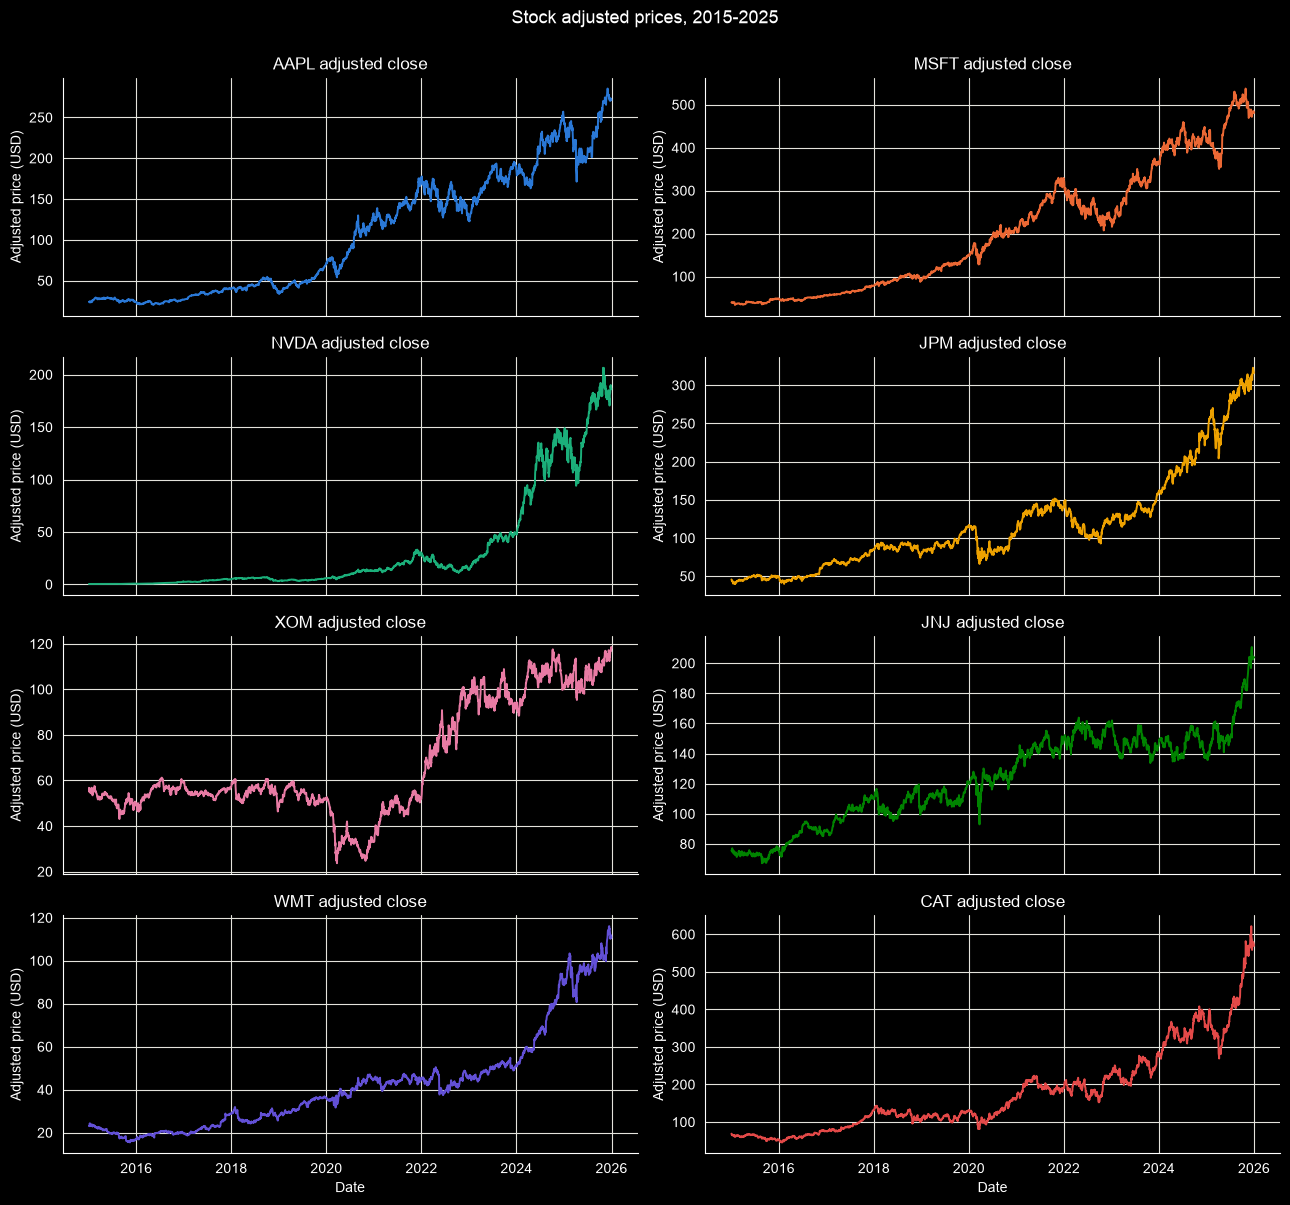

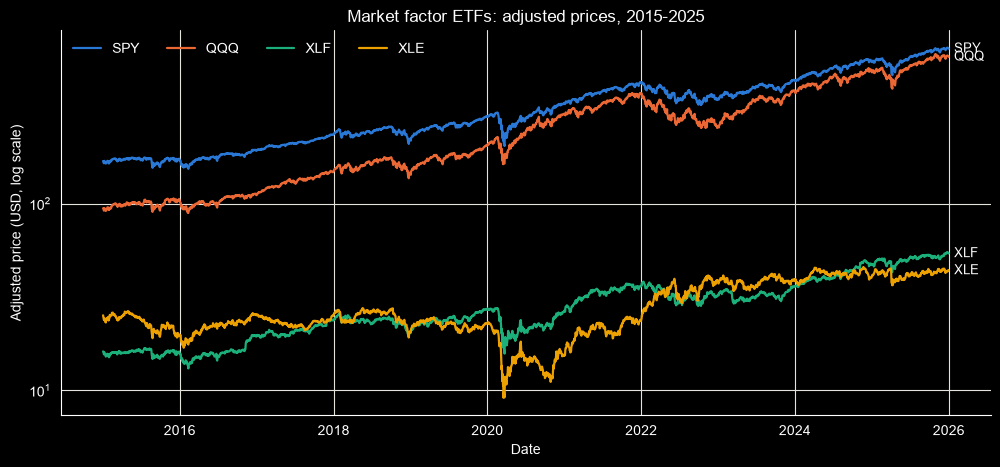

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
for ax, t in zip(axes.flat, STOCKS):
    ax.plot(prices.index, prices[t], color=STOCK_COLORS[t], linewidth=1.4)
    ax.set_title(f"{t} adjusted close")
    ax.set_ylabel("Adjusted price (USD)")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in axes[-1]:
    ax.set_xlabel("Date")
fig.suptitle("Stock adjusted prices, 2015-2025", y=1.0, fontsize=13)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
for t in FACTORS:
    ax.plot(prices.index, prices[t], color=FACTOR_COLORS[t], linewidth=1.6, label=t)
    ax.annotate(t, xy=(prices.index[-1], prices[t].iloc[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=9)
ax.set_yscale("log")
ax.set_ylabel("Adjusted price (USD, log scale)")
ax.set_xlabel("Date")
ax.set_title("Market factor ETFs: adjusted prices, 2015-2025")
ax.legend(frameon=False, ncol=4, loc="upper left")
plt.show()

## 7. Daily returns

In [7]:
returns = prices.pct_change(fill_method=None)

display(returns.head())
display(returns.describe().T.assign(count=lambda d: d["count"].astype(int)))
display(returns.isna().sum().to_frame("missing_returns").T)
print("First row is NaN by construction (no previous price); nothing is filled with zero.")

,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT,SPY,QQQ,XLF,XLE
date,,,,,,,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-05,-0.028172,-0.009196,-0.016890,-0.031045,-0.027362,-0.006984,-0.002910,-0.052786,-0.018059,-0.014669,-0.021027,-0.041368
2015-01-06,0.000094,-0.014677,-0.030318,-0.025929,-0.005316,-0.004914,0.007706,-0.006435,-0.009419,-0.013409,-0.015282,-0.014690
2015-01-07,0.014022,0.012705,-0.002605,0.001526,0.010133,0.022076,0.026533,0.015497,0.012461,0.012891,0.010486,0.002130
2015-01-08,0.038422,0.029418,0.037617,0.022347,0.016645,0.007862,0.021106,0.010250,0.017745,0.019140,0.014944,0.022449


,count,mean,std,min,25%,50%,75%,max
AAPL,2765,0.001039,0.018171,-0.128647,-0.007282,0.000951,0.010014,0.153289
MSFT,2765,0.001046,0.016938,-0.147390,-0.006727,0.000954,0.009428,0.142169
NVDA,2765,0.002622,0.030673,-0.187558,-0.012402,0.002648,0.017714,0.298067
JPM,2765,0.000845,0.017102,-0.149649,-0.007009,0.000690,0.008935,0.180125
XOM,2765,0.000414,0.017271,-0.122248,-0.008183,0.000262,0.009025,0.126868
JNJ,2765,0.000424,0.011465,-0.100379,-0.004872,0.000462,0.005999,0.079977
WMT,2765,0.000659,0.013551,-0.113757,-0.005622,0.000738,0.007080,0.117085
CAT,2765,0.000942,0.018880,-0.142822,-0.008565,0.000714,0.010812,0.116346
SPY,2765,0.000564,0.011208,-0.109424,-0.003705,0.000637,0.005925,0.105019
QQQ,2765,0.000772,0.013847,-0.119788,-0.005002,0.001227,0.007803,0.120031


,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT,SPY,QQQ,XLF,XLE
missing_returns,1,1,1,1,1,1,1,1,1,1,1,1


First row is NaN by construction (no previous price); nothing is filled with zero.


## 8. Return-distribution charts

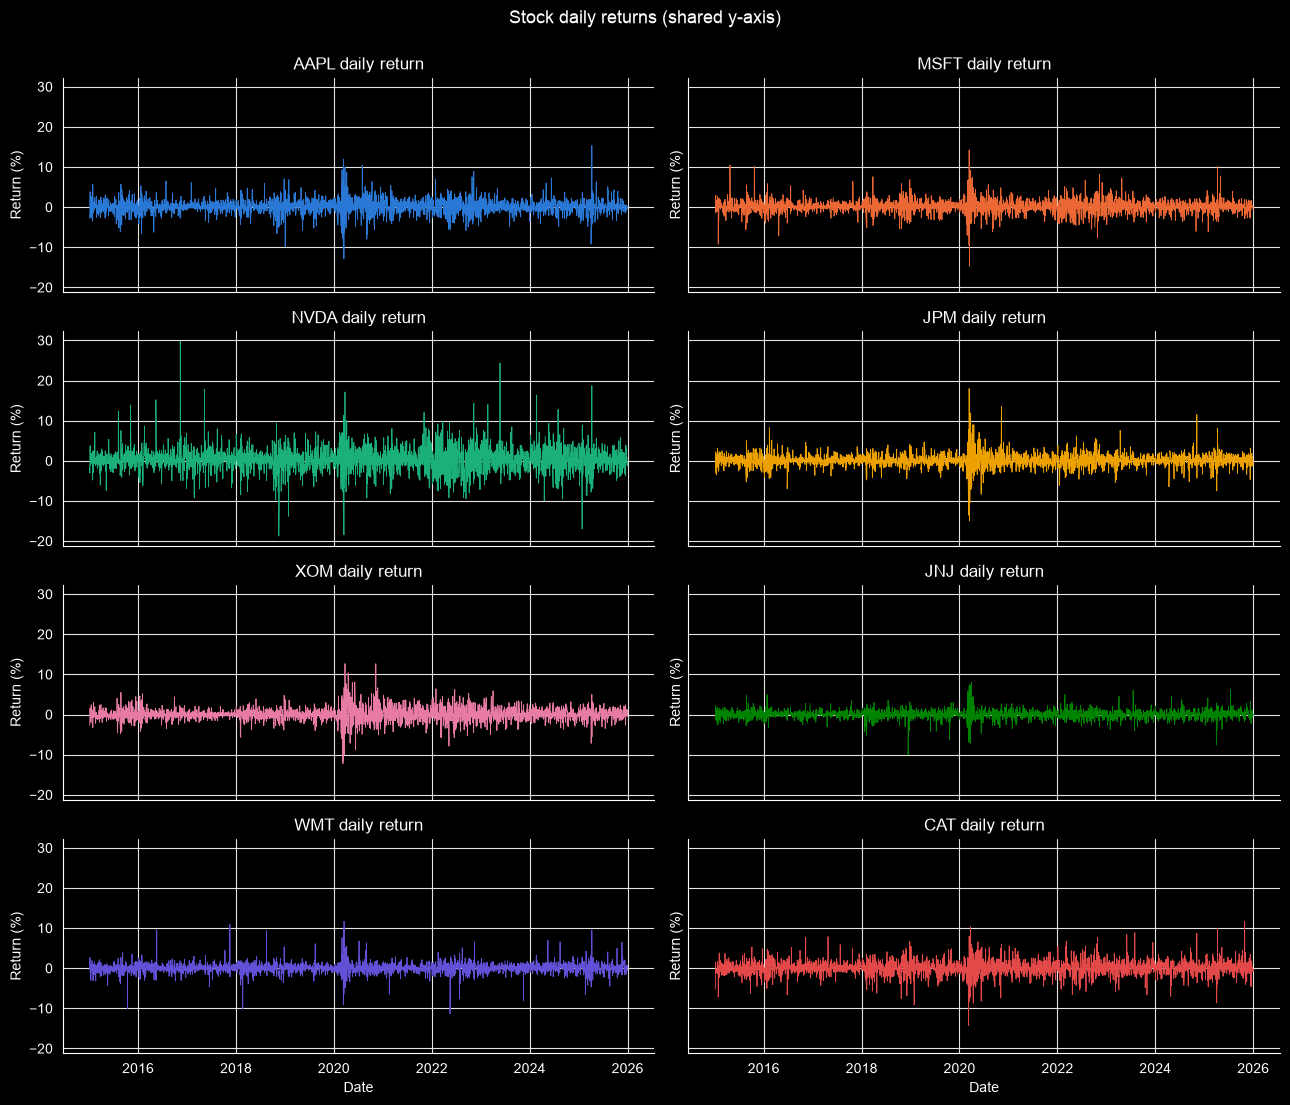

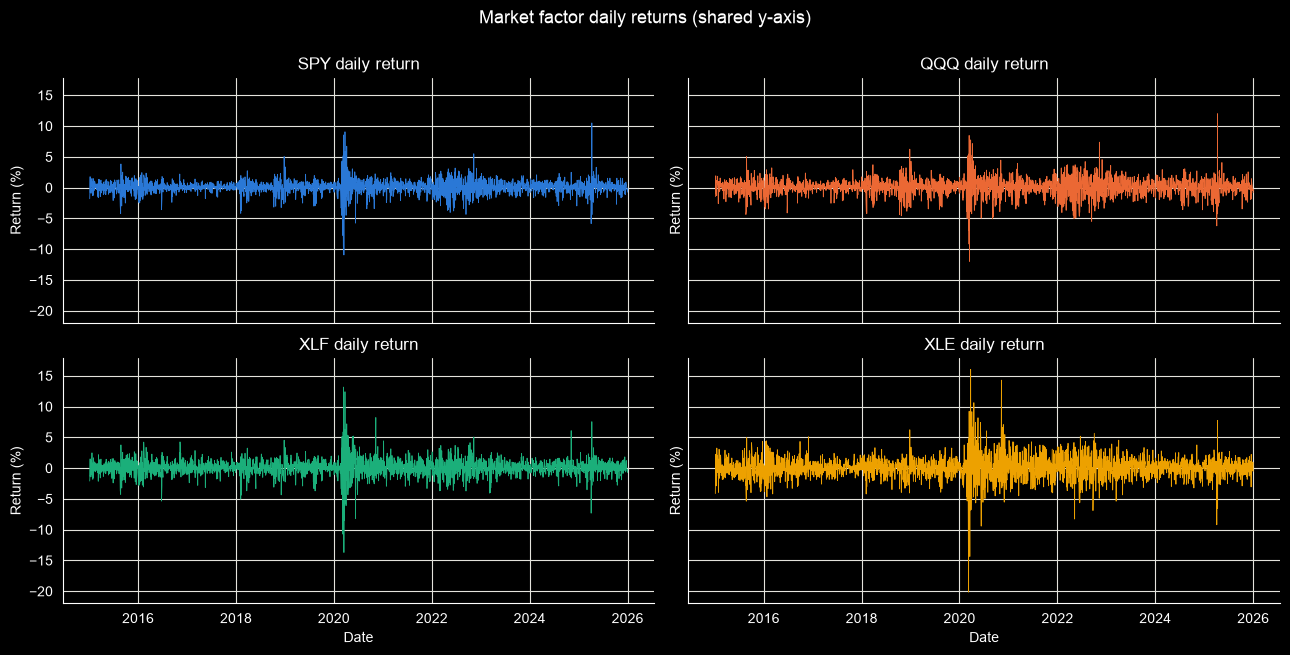

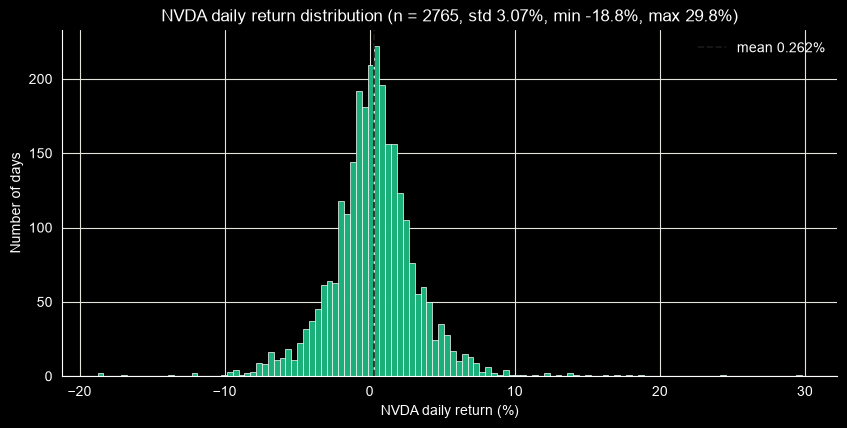

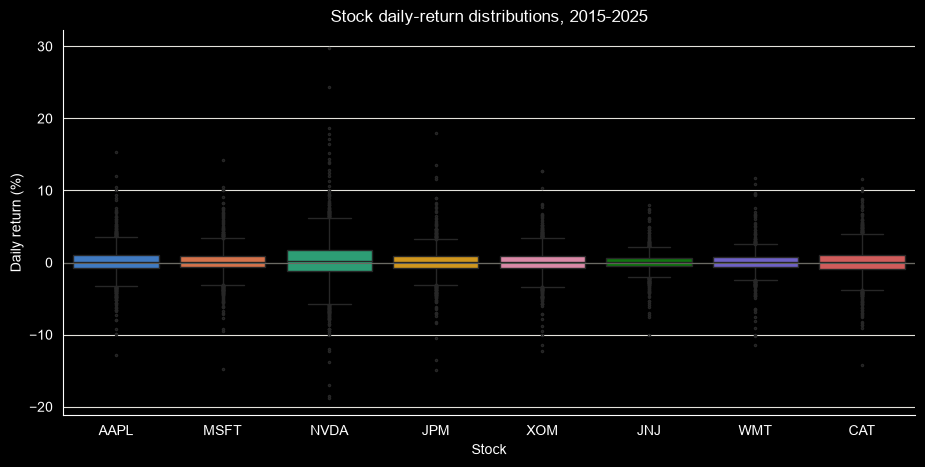

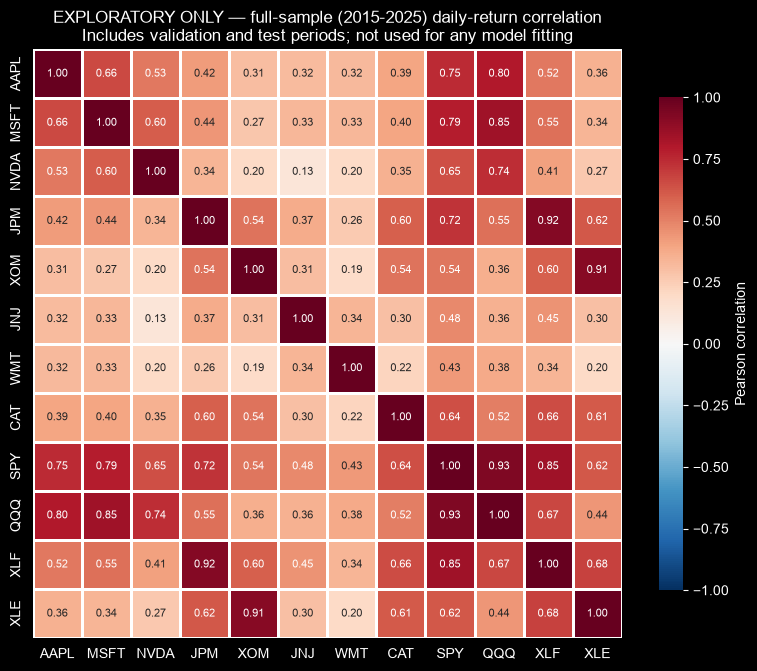

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True, sharey=True)
for ax, t in zip(axes.flat, STOCKS):
    ax.plot(returns.index, returns[t] * 100, color=STOCK_COLORS[t], linewidth=0.6)
    ax.set_title(f"{t} daily return")
    ax.set_ylabel("Return (%)")
for ax in axes[-1]:
    ax.set_xlabel("Date")
fig.suptitle("Stock daily returns (shared y-axis)", y=1.0, fontsize=13)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, sharey=True)
for ax, t in zip(axes.flat, FACTORS):
    ax.plot(returns.index, returns[t] * 100, color=FACTOR_COLORS[t], linewidth=0.6)
    ax.set_title(f"{t} daily return")
    ax.set_ylabel("Return (%)")
for ax in axes[-1]:
    ax.set_xlabel("Date")
fig.suptitle("Market factor daily returns (shared y-axis)", y=1.0, fontsize=13)
fig.tight_layout()
plt.show()

nvda = returns["NVDA"].dropna() * 100
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(nvda, bins=120, color=STOCK_COLORS["NVDA"], edgecolor="white", linewidth=0.5)
ax.axvline(nvda.mean(), color="#1a1a19", linewidth=1.2, linestyle="--", label=f"mean {nvda.mean():.3f}%")
ax.set_xlabel("NVDA daily return (%)")
ax.set_ylabel("Number of days")
ax.set_title(f"NVDA daily return distribution (n = {len(nvda)}, std {nvda.std():.2f}%, "
             f"min {nvda.min():.1f}%, max {nvda.max():.1f}%)")
ax.legend(frameon=False)
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
long = (returns[STOCKS] * 100).melt(var_name="stock", value_name="return_pct").dropna()
sns.boxplot(data=long, x="stock", y="return_pct", hue="stock", palette=STOCK_COLORS, legend=False,
            fliersize=1.5, linewidth=1, ax=ax)
ax.axhline(0, color="#6b6a63", linewidth=0.8)
ax.set_xlabel("Stock")
ax.set_ylabel("Daily return (%)")
ax.set_title("Stock daily-return distributions, 2015-2025")
plt.show()

corr_full = returns.corr()
fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(corr_full, vmin=-1, vmax=1, center=0, cmap="RdBu_r", annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, square=True, linewidths=1, linecolor="white",
            cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.grid(False)
ax.set_title("EXPLORATORY ONLY — full-sample (2015-2025) daily-return correlation\n"
             "Includes validation and test periods; not used for any model fitting")
plt.show()

## 9. Build the model dataset

In [9]:
returns_named = returns.rename(columns=lambda t: f"{t}_return")
STOCK_COLS = [f"{t}_return" for t in STOCKS]
FACTOR_COLS = [f"{t}_return" for t in FACTORS]
MODEL_COLS = STOCK_COLS + FACTOR_COLS
returns_named = returns_named[MODEL_COLS]

# Complete-case rows: a portfolio return, a covariance/correlation matrix and a factor
# regression all need every stock and factor observed on the same date.
incomplete = returns_named.isna().any(axis=1)
dropped = returns_named[incomplete]
model_data = returns_named[~incomplete].copy()

drop_report = pd.DataFrame(
    {
        "date": dropped.index.date,
        "missing_columns": [", ".join(c for c in MODEL_COLS if pd.isna(row[c])) for _, row in dropped.iterrows()],
    }
)
print(f"Rows before: {len(returns_named)}   rows dropped: {len(dropped)}   rows kept: {len(model_data)}")
display(drop_report.style.hide(axis="index"))
print("Calculations that need complete observations: portfolio returns (all 8 stocks), "
      "covariance/correlation matrices, and stock-on-factor regressions (all 12 columns).")
display(model_data.head())
print("Shape:", model_data.shape)

Rows before: 2766   rows dropped: 1   rows kept: 2765


date,missing_columns
2015-01-02,"AAPL_return, MSFT_return, NVDA_return, JPM_return, XOM_return, JNJ_return, WMT_return, CAT_return, SPY_return, QQQ_return, XLF_return, XLE_return"


Calculations that need complete observations: portfolio returns (all 8 stocks), covariance/correlation matrices, and stock-on-factor regressions (all 12 columns).


,AAPL_return,MSFT_return,NVDA_return,JPM_return,XOM_return,JNJ_return,WMT_return,CAT_return,SPY_return,QQQ_return,XLF_return,XLE_return
date,,,,,,,,,,,,
2015-01-05,-0.028172,-0.009196,-0.016890,-0.031045,-0.027362,-0.006984,-0.002910,-0.052786,-0.018059,-0.014669,-0.021027,-0.041368
2015-01-06,0.000094,-0.014677,-0.030318,-0.025929,-0.005316,-0.004914,0.007706,-0.006435,-0.009419,-0.013409,-0.015282,-0.014690
2015-01-07,0.014022,0.012705,-0.002605,0.001526,0.010133,0.022076,0.026533,0.015497,0.012461,0.012891,0.010486,0.002130
2015-01-08,0.038422,0.029418,0.037617,0.022347,0.016645,0.007862,0.021106,0.010250,0.017745,0.019140,0.014944,0.022449
2015-01-09,0.001073,-0.008405,0.004028,-0.017387,-0.001410,-0.013629,-0.012380,-0.011949,-0.008013,-0.006583,-0.013498,-0.007925


Shape: (2765, 12)


## 10. Chronological data splits

In [10]:
split_frames = {name: model_data.loc[s:e] for name, (s, e) in SPLITS.items()}
train_data, validation_data, test_data = split_frames["train"], split_frames["validation"], split_frames["test"]

split_summary = pd.DataFrame(
    [
        {"split": name, "configured_start": s.date(), "configured_end": e.date(),
         "first_date": df.index.min().date(), "last_date": df.index.max().date(),
         "rows": len(df), "columns": df.shape[1]}
        for (name, (s, e)), df in zip(SPLITS.items(), split_frames.values())
    ]
)
display(split_summary.style.hide(axis="index"))

for name, df in split_frames.items():
    s, e = SPLITS[name]
    assert df.index.is_monotonic_increasing, f"{name} not chronological"
    assert df.index.min() >= s and df.index.max() <= e, f"{name} has dates outside {s.date()}..{e.date()}"
assert train_data.index.max() < validation_data.index.min(), "train overlaps validation"
assert validation_data.index.max() < test_data.index.min(), "validation overlaps test"
assert not (set(train_data.index) & set(validation_data.index) | set(validation_data.index) & set(test_data.index)
            | set(train_data.index) & set(test_data.index)), "a date appears in two splits"
assert sum(len(df) for df in split_frames.values()) == len(model_data), "rows lost or duplicated by splitting"
print("Splits are chronological, non-overlapping, inside their configured ranges, and cover every model row.")

split,configured_start,configured_end,first_date,last_date,rows,columns
train,2015-01-01,2021-12-31,2015-01-05,2021-12-31,1762,12
validation,2022-01-01,2023-12-31,2022-01-03,2023-12-29,501,12
test,2024-01-01,2025-12-31,2024-01-02,2025-12-31,502,12


Splits are chronological, non-overlapping, inside their configured ranges, and cover every model row.


## 11. Training-period correlation analysis

,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT,SPY,QQQ,XLF,XLE
AAPL,1.000,0.683,0.537,0.439,0.354,0.400,0.337,0.416,0.734,0.821,0.511,0.391
MSFT,0.683,1.000,0.586,0.485,0.372,0.481,0.380,0.442,0.798,0.873,0.568,0.418
NVDA,0.537,0.586,1.000,0.338,0.273,0.277,0.258,0.352,0.599,0.691,0.410,0.313
JPM,0.439,0.485,0.338,1.000,0.650,0.444,0.279,0.642,0.763,0.568,0.946,0.710
XOM,0.354,0.372,0.273,0.650,1.000,0.399,0.229,0.605,0.652,0.464,0.694,0.909
JNJ,0.400,0.481,0.277,0.444,0.399,1.000,0.405,0.404,0.631,0.529,0.515,0.381
WMT,0.337,0.380,0.258,0.279,0.229,0.405,1.000,0.269,0.465,0.429,0.344,0.212
CAT,0.416,0.442,0.352,0.642,0.605,0.404,0.269,1.000,0.677,0.537,0.691,0.654
SPY,0.734,0.798,0.599,0.763,0.652,0.631,0.465,0.677,1.000,0.921,0.864,0.707
QQQ,0.821,0.873,0.691,0.568,0.464,0.529,0.429,0.537,0.921,1.000,0.667,0.513


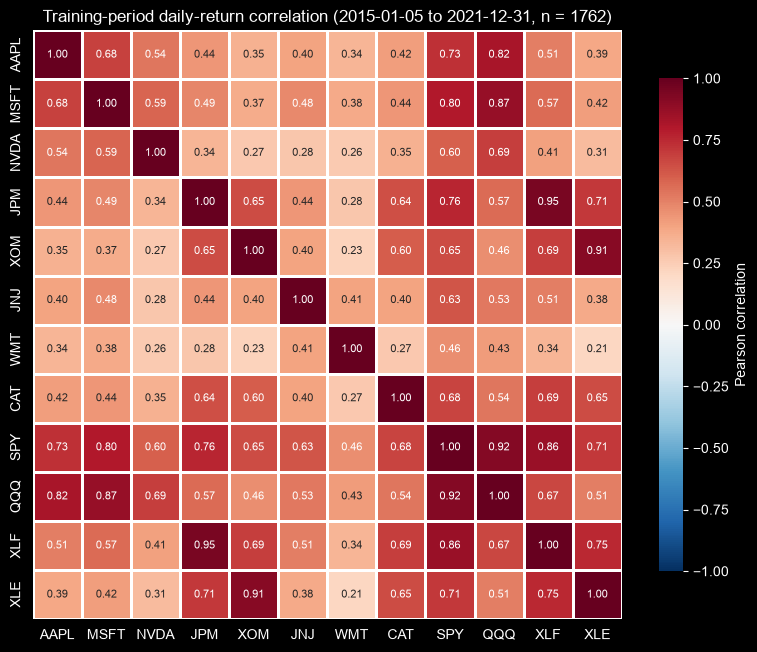

Stock-to-factor training correlations (highest factor per stock):


,SPY,QQQ,XLF,XLE,highest,value
AAPL,0.734154,0.821043,0.510547,0.390507,QQQ,0.821
MSFT,0.798067,0.873427,0.567852,0.418462,QQQ,0.873
NVDA,0.599006,0.691401,0.409644,0.312907,QQQ,0.691
JPM,0.763177,0.567943,0.945794,0.710396,XLF,0.946
XOM,0.652295,0.463630,0.693661,0.908776,XLE,0.909
JNJ,0.630625,0.528813,0.514523,0.380702,SPY,0.631
WMT,0.464981,0.429138,0.343717,0.211970,SPY,0.465
CAT,0.676637,0.536618,0.691216,0.654094,XLF,0.691


In [11]:
corr_train = train_data.corr()
corr_train_display = corr_train.rename(index=lambda c: c.removesuffix("_return"),
                                       columns=lambda c: c.removesuffix("_return"))
display(corr_train_display.round(3))

fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(corr_train_display, vmin=-1, vmax=1, center=0, cmap="RdBu_r", annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, square=True, linewidths=1, linecolor="white",
            cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.grid(False)
ax.set_title(f"Training-period daily-return correlation "
             f"({train_data.index.min().date()} to {train_data.index.max().date()}, n = {len(train_data)})")
plt.show()

pairs = corr_train_display.loc[STOCKS, FACTORS]
print("Stock-to-factor training correlations (highest factor per stock):")
display(pairs.assign(highest=pairs.idxmax(axis=1), value=pairs.max(axis=1).round(3)))

## 12. Save processed datasets

In [12]:
OUTPUTS = {
    "processed prices": (prices, PROCESSED_DIR / "prices" / f"adj_close_prices_processed_{RANGE_TAG}.csv"),
    "daily returns (NaN kept)": (returns_named, PROCESSED_DIR / "returns" / f"daily_returns_processed_{RANGE_TAG}.csv"),
    "model dataset (complete case)": (model_data, PROCESSED_DIR / "returns" / f"model_returns_processed_{RANGE_TAG}.csv"),
}
for name, df in split_frames.items():
    s, e = SPLITS[name]
    OUTPUTS[f"{name} split"] = (df, PROCESSED_DIR / "splits" / f"{name}_model_returns_{s.date()}_{e.date()}.csv")

for label, (df, path) in OUTPUTS.items():
    save_checked(df, path)

saved_table = pd.DataFrame(
    [{"dataset": "raw prices", "path": str(RAW_PRICES_PATH), "status": SAVED[RAW_PRICES_PATH]}]
    + [{"dataset": label, "path": str(path), "status": SAVED[path]} for label, (_, path) in OUTPUTS.items()]
)
display(saved_table.style.hide(axis="index"))

dataset,path,status
raw prices,RS-RL/data/raw/adj_close_prices_raw_2015-01-01_2025-12-31.csv,"exists, identical (not rewritten)"
processed prices,RS-RL/data/processed/prices/adj_close_prices_processed_2015-01-01_2025-12-31.csv,"exists, identical (not rewritten)"
daily returns (NaN kept),RS-RL/data/processed/returns/daily_returns_processed_2015-01-01_2025-12-31.csv,"exists, identical (not rewritten)"
model dataset (complete case),RS-RL/data/processed/returns/model_returns_processed_2015-01-01_2025-12-31.csv,"exists, identical (not rewritten)"
train split,RS-RL/data/processed/splits/train_model_returns_2015-01-01_2021-12-31.csv,"exists, identical (not rewritten)"
validation split,RS-RL/data/processed/splits/validation_model_returns_2022-01-01_2023-12-31.csv,"exists, identical (not rewritten)"
test split,RS-RL/data/processed/splits/test_model_returns_2024-01-01_2025-12-31.csv,"exists, identical (not rewritten)"


## 13. Final validation

In [13]:
results = []

def check(name, fn):
    try:
        ok = bool(fn())
        detail = ""
    except Exception as exc:
        ok, detail = False, f"{type(exc).__name__}: {exc}"
    results.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})

def reread(path):
    return pd.read_csv(path, parse_dates=["date"], index_col="date")

# Independent reference: the original raw yfinance files, read again from disk.
reference = pd.concat({t: load_raw_adj_close(t) for t in TICKERS}, axis=1).loc[str(START):str(END)]
reference = reference[~reference.index.duplicated(keep="first")].sort_index()
manual_returns = prices / prices.shift(1) - 1

# Project's own processed panels (written by the Stage 2 pipeline) as a second cross-check.
proc_stock = pd.read_csv(PROCESSED_DIR / "prices" / "stock_prices.csv", parse_dates=["date"], index_col="date")
proc_factor = pd.read_csv(PROCESSED_DIR / "prices" / "market_indicator_prices.csv", parse_dates=["date"], index_col="date")
proc_adj = pd.concat([proc_stock, proc_factor], axis=1)[[f"{t}_adj_close" for t in TICKERS]]
proc_adj.columns = TICKERS

check("All 8 stock columns present", lambda: all(c in model_data for c in STOCK_COLS))
check("All 4 factor columns present", lambda: all(c in model_data for c in FACTOR_COLS))
check("Price dates sorted and unique", lambda: prices.index.is_monotonic_increasing and prices.index.is_unique)
check("Model dates sorted and unique", lambda: model_data.index.is_monotonic_increasing and model_data.index.is_unique)
check("Prices identical to raw yfinance files (no synthetic values)",
      lambda: prices.equals(reference))
check("Prices match project processed price panels",
      lambda: np.allclose(prices, proc_adj.reindex(prices.index), rtol=1e-12, atol=0, equal_nan=True))
check("All prices strictly positive", lambda: bool((prices.dropna(how="all") > 0).stack().all()))
check("Missing returns not replaced with zero",
      lambda: returns.isna().sum().equals((prices.isna() | prices.shift(1).isna()).sum()))
check("First return row is NaN (not 0)", lambda: returns.iloc[0].isna().all())
check("Returns equal p_t / p_(t-1) - 1",
      lambda: np.allclose(returns, manual_returns, rtol=0, atol=1e-15, equal_nan=True))
check("Model dataset has no NaN", lambda: not model_data.isna().any().any())
check("Model values equal pct_change returns",
      lambda: model_data.equals(returns_named.loc[model_data.index]))
check("Train/validation/test do not overlap",
      lambda: train_data.index.max() < validation_data.index.min() and validation_data.index.max() < test_data.index.min())
for name, df in split_frames.items():
    s, e = SPLITS[name]
    check(f"{name} within {s.date()}..{e.date()}", lambda df=df, s=s, e=e: df.index.min() >= s and df.index.max() <= e)
check("Dataset within 2015-01-01..2025-12-31",
      lambda: model_data.index.min() >= pd.Timestamp(START) and model_data.index.max() <= pd.Timestamp(END))
check("Saved files exist", lambda: all(p.is_file() for p in SAVED))
def read_back_identical():
    for df, p in [(prices, RAW_PRICES_PATH)] + list(OUTPUTS.values()):
        pd.testing.assert_frame_equal(reread(p), df, check_freq=False)
    return True

check("Saved files read back identical", read_back_identical)

validation_df = pd.DataFrame(results)
display(validation_df.style.hide(axis="index").map(
    lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""),
    subset=["result"]))

n_pass = int((validation_df["result"] == "PASS").sum())
print(f"{n_pass}/{len(validation_df)} checks PASS")
assert n_pass == len(validation_df), f"Failed checks: {validation_df.loc[validation_df.result == 'FAIL', 'check'].tolist()}"
print("STAGE 2 COMPLETE")

check,result,detail
All 8 stock columns present,PASS,
All 4 factor columns present,PASS,
Price dates sorted and unique,PASS,
Model dates sorted and unique,PASS,
Prices identical to raw yfinance files (no synthetic values),PASS,
Prices match project processed price panels,PASS,
All prices strictly positive,PASS,
Missing returns not replaced with zero,PASS,
First return row is NaN (not 0),PASS,
Returns equal p_t / p_(t-1) - 1,PASS,


19/19 checks PASS
STAGE 2 COMPLETE
